In [4]:

import os
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, transforms

from sklearn.metrics import confusion_matrix, classification_report

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Device configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch Version:", torch.__version__)
print("Device:", DEVICE)


PyTorch Version: 2.15.0+cpu
Device: cpu


In [5]:

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

NUM_CLASSES = 10

for i, name in enumerate(class_names):
    print(i, "-", name)


0 - T-shirt/top
1 - Trouser
2 - Pullover
3 - Dress
4 - Coat
5 - Sandal
6 - Shirt
7 - Sneaker
8 - Bag
9 - Ankle boot


In [6]:

class FashionMNISTCSV(Dataset):
    def __init__(self, file_path):
        df = pd.read_csv(file_path)

        self.labels = torch.tensor(
            df.iloc[:, 0].values, dtype=torch.long
        )

        self.images = torch.tensor(
            df.iloc[:, 1:].values, dtype=torch.float32
        ).reshape(-1, 1, 28, 28) / 255.0

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.images[index], self.labels[index]


train_csv = None
test_csv = None

for folder in [".", "data"]:
    if os.path.exists(os.path.join(folder, "fashion-mnist_train.csv")):
        train_csv = os.path.join(folder, "fashion-mnist_train.csv")
        test_csv = os.path.join(folder, "fashion-mnist_test.csv")
        break

if train_csv and os.path.exists(test_csv):

    full_train_dataset = FashionMNISTCSV(train_csv)
    test_dataset = FashionMNISTCSV(test_csv)

    print("Dataset loaded from Kaggle CSV files.")

else:

    transform = transforms.ToTensor()

    full_train_dataset = datasets.FashionMNIST(
        root="./data",
        train=True,
        transform=transform,
        download=True
    )

    test_dataset = datasets.FashionMNIST(
        root="./data",
        train=False,
        transform=transform,
        download=True
    )

    print("Dataset loaded using torchvision.")

print("Training dataset:", len(full_train_dataset))
print("Testing dataset:", len(test_dataset))


Dataset loaded from Kaggle CSV files.
Training dataset: 60000
Testing dataset: 10000


In [7]:

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))


Training samples: 48000
Validation samples: 12000
Testing samples: 10000


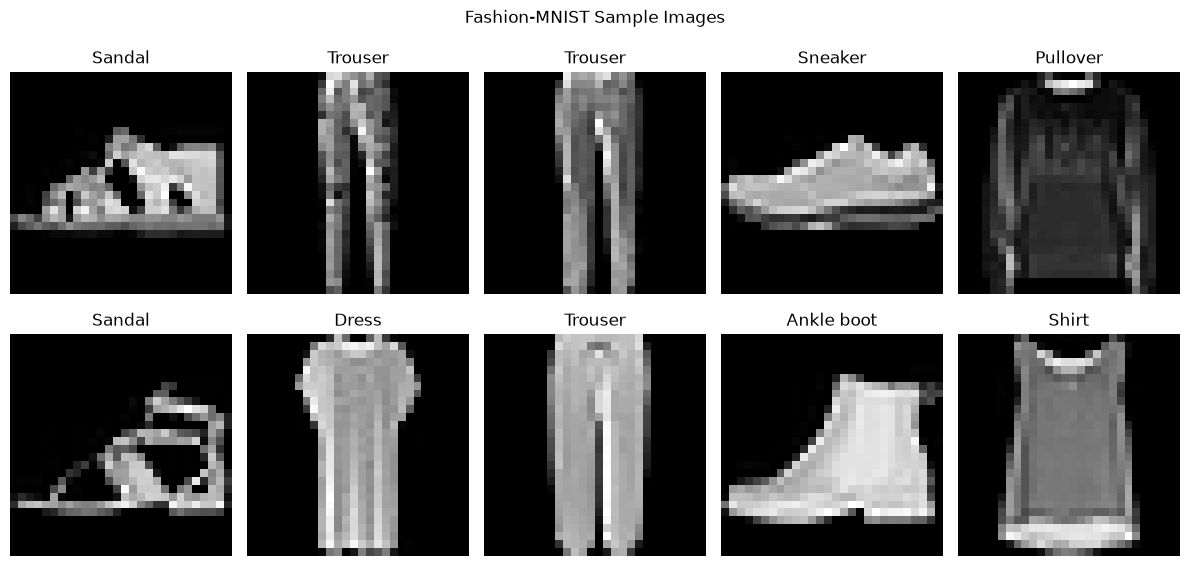

In [8]:

images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(class_names[labels[i].item()])
    plt.axis("off")

plt.suptitle("Fashion-MNIST Sample Images")
plt.tight_layout()
plt.show()


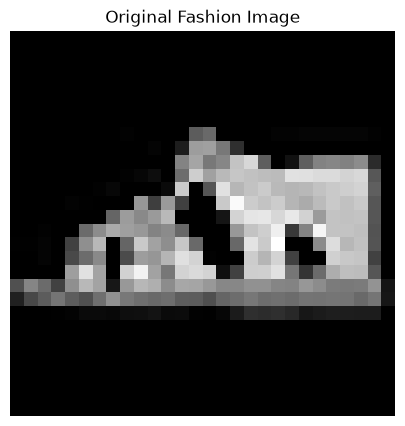

Image Shape: (28, 28)


In [9]:

sample_image = images[0].squeeze().numpy()

plt.figure(figsize=(5, 5))
plt.imshow(sample_image, cmap="gray")
plt.title("Original Fashion Image")
plt.axis("off")
plt.show()

print("Image Shape:", sample_image.shape)


In [10]:

def convolution_2d(image, kernel, stride=1, padding=0):

    image = np.pad(
        image,
        ((padding, padding), (padding, padding)),
        mode="constant"
    )

    image_height, image_width = image.shape
    kernel_height, kernel_width = kernel.shape

    output_height = (
        (image_height - kernel_height) // stride
    ) + 1

    output_width = (
        (image_width - kernel_width) // stride
    ) + 1

    output = np.zeros((output_height, output_width))

    for i in range(output_height):
        for j in range(output_width):

            region = image[
                i * stride : i * stride + kernel_height,
                j * stride : j * stride + kernel_width
            ]

            output[i, j] = np.sum(region * kernel)

    return output


In [11]:

sobel_horizontal = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

sobel_vertical = np.array([
    [-1,  0,  1],
    [-2,  0,  2],
    [-1,  0,  1]
])

blur_filter = np.ones((3, 3)) / 9

print("Horizontal Sobel Filter:\n", sobel_horizontal)
print("\nVertical Sobel Filter:\n", sobel_vertical)
print("\nBlur Filter:\n", blur_filter)


Horizontal Sobel Filter:
 [[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]

Vertical Sobel Filter:
 [[-1  0  1]
 [-2  0  2]
 [-1  0  1]]

Blur Filter:
 [[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


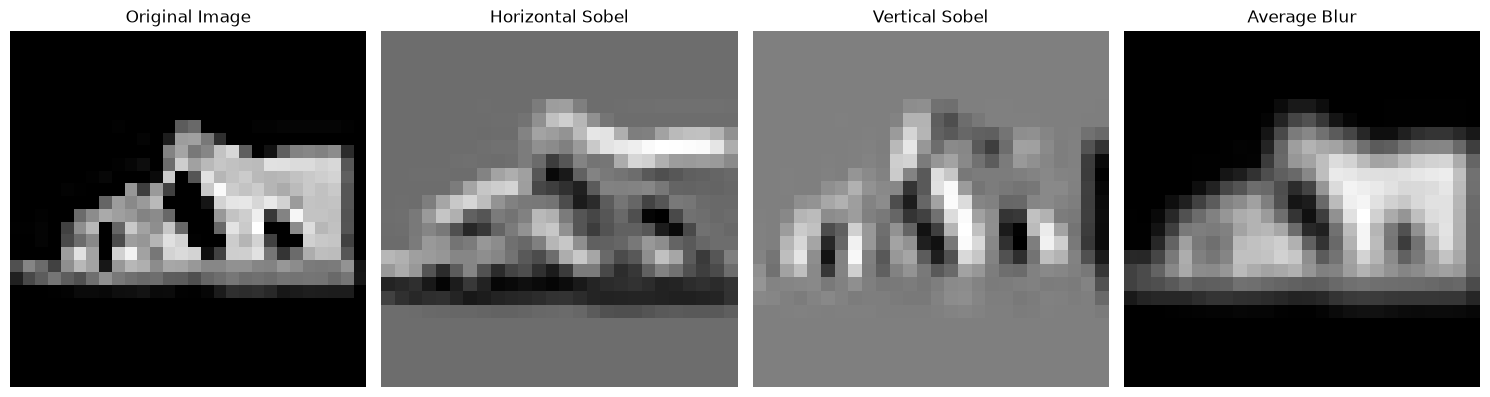

In [12]:

horizontal_output = convolution_2d(
    sample_image, sobel_horizontal
)

vertical_output = convolution_2d(
    sample_image, sobel_vertical
)

blur_output = convolution_2d(
    sample_image, blur_filter
)

plt.figure(figsize=(15, 4))

outputs = [
    (sample_image, "Original Image", "gray"),
    (horizontal_output, "Horizontal Sobel", "gray"),
    (vertical_output, "Vertical Sobel", "gray"),
    (blur_output, "Average Blur", "gray")
]

for i, (output, title, cmap) in enumerate(outputs):
    plt.subplot(1, 4, i + 1)
    plt.imshow(output, cmap=cmap)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [13]:

input_size = 28
kernel_size = 3
stride = 1
padding = 0

output_size = (
    input_size - kernel_size + 2 * padding
) // stride + 1

print("Input Image Size:", input_size, "x", input_size)
print("Kernel Size:", kernel_size, "x", kernel_size)
print("Output Size:", output_size, "x", output_size)


Input Image Size: 28 x 28
Kernel Size: 3 x 3
Output Size: 26 x 26


In [14]:

def max_pooling_2d(feature_map, pool_size=2, stride=2):

    height, width = feature_map.shape

    output_height = (height - pool_size) // stride + 1
    output_width = (width - pool_size) // stride + 1

    output = np.zeros((output_height, output_width))

    for i in range(output_height):
        for j in range(output_width):

            region = feature_map[
                i * stride : i * stride + pool_size,
                j * stride : j * stride + pool_size
            ]

            output[i, j] = np.max(region)

    return output


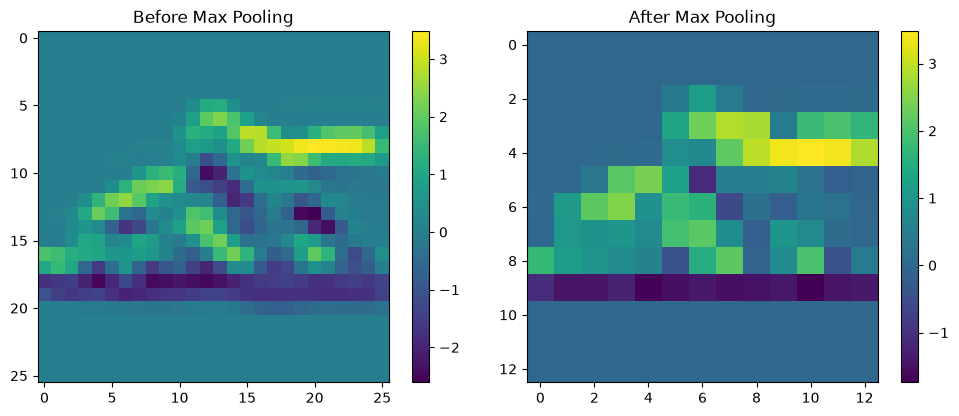

Before Pooling: (26, 26)
After Pooling: (13, 13)


In [15]:

feature_map = horizontal_output

pooled_output = max_pooling_2d(
    feature_map,
    pool_size=2,
    stride=2
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(feature_map, cmap="viridis")
plt.title("Before Max Pooling")
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(pooled_output, cmap="viridis")
plt.title("After Max Pooling")
plt.colorbar()

plt.tight_layout()
plt.show()

print("Before Pooling:", feature_map.shape)
print("After Pooling:", pooled_output.shape)


In [16]:

class SimpleCNN(nn.Module):

    def __init__(self):
        super(SimpleCNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(64 * 5 * 5, 128)
        self.relu3 = nn.ReLU()

        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)

        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu3(x)

        x = self.fc2(x)

        return x


simple_model = SimpleCNN().to(DEVICE)

print(simple_model)


SimpleCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [17]:

class ImprovedCNN(nn.Module):

    def __init__(self, use_bn=False, use_dropout=False):
        super(ImprovedCNN, self).__init__()

        self.use_bn = use_bn
        self.use_dropout = use_dropout

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3)
        self.bn1 = nn.BatchNorm2d(32) if use_bn else nn.Identity()

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3)
        self.bn2 = nn.BatchNorm2d(64) if use_bn else nn.Identity()

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2, 2)

        self.dropout_conv = nn.Dropout2d(0.25)
        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(64 * 5 * 5, 128)
        self.dropout_fc = nn.Dropout(0.5)

        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        if self.use_dropout:
            x = self.dropout_conv(x)

        x = self.pool(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu(x)

        if self.use_dropout:
            x = self.dropout_conv(x)

        x = self.pool(x)

        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu(x)

        if self.use_dropout:
            x = self.dropout_fc(x)

        x = self.fc2(x)

        return x


bn_model = ImprovedCNN(
    use_bn=True,
    use_dropout=False
).to(DEVICE)

dropout_model = ImprovedCNN(
    use_bn=True,
    use_dropout=True
).to(DEVICE)

print("Batch Normalization CNN:")
print(bn_model)

print("\nBatch Normalization + Dropout CNN:")
print(dropout_model)


Batch Normalization CNN:
ImprovedCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout_conv): Dropout2d(p=0.25, inplace=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (dropout_fc): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Batch Normalization + Dropout CNN:
ImprovedCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))


In [18]:

LEARNING_RATE = 0.001
EPOCHS = 20

criterion = nn.CrossEntropyLoss()

def create_optimizer(model):
    return optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

print("Loss Function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)


Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.001
Epochs: 20


In [19]:

def evaluate_model(model, loader):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for inputs, labels in loader:

            inputs = inputs.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy


def train_model(model, model_name):

    optimizer = create_optimizer(model)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_accuracy = 0
    best_weights = copy.deepcopy(model.state_dict())

    start_time = time.time()

    for epoch in range(EPOCHS):

        model.train()

        running_loss = 0
        correct = 0
        total = 0

        for inputs, labels in train_loader:

            inputs = inputs.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_accuracy = correct / total

        val_loss, val_accuracy = evaluate_model(
            model, val_loader
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"{model_name} | Epoch {epoch + 1}/{EPOCHS} "
            f"| Train Acc: {train_accuracy:.4f} "
            f"| Val Acc: {val_accuracy:.4f} "
            f"| Train Loss: {train_loss:.4f} "
            f"| Val Loss: {val_loss:.4f}"
        )

    training_time = time.time() - start_time

    model.load_state_dict(best_weights)

    print("\nBest Validation Accuracy:", round(best_accuracy, 4))
    print("Training Time:", round(training_time, 2), "seconds")

    return model, history, training_time


In [20]:

simple_model, simple_history, simple_time = train_model(
    simple_model,
    "Simple CNN"
)


Simple CNN | Epoch 1/20 | Train Acc: 0.7741 | Val Acc: 0.8451 | Train Loss: 0.6242 | Val Loss: 0.4281
Simple CNN | Epoch 2/20 | Train Acc: 0.8636 | Val Acc: 0.8710 | Train Loss: 0.3822 | Val Loss: 0.3601
Simple CNN | Epoch 3/20 | Train Acc: 0.8786 | Val Acc: 0.8884 | Train Loss: 0.3361 | Val Loss: 0.3129
Simple CNN | Epoch 4/20 | Train Acc: 0.8896 | Val Acc: 0.8887 | Train Loss: 0.3030 | Val Loss: 0.3034
Simple CNN | Epoch 5/20 | Train Acc: 0.8977 | Val Acc: 0.8895 | Train Loss: 0.2801 | Val Loss: 0.3085
Simple CNN | Epoch 6/20 | Train Acc: 0.9049 | Val Acc: 0.8964 | Train Loss: 0.2598 | Val Loss: 0.2815
Simple CNN | Epoch 7/20 | Train Acc: 0.9119 | Val Acc: 0.8988 | Train Loss: 0.2394 | Val Loss: 0.2794
Simple CNN | Epoch 8/20 | Train Acc: 0.9178 | Val Acc: 0.9048 | Train Loss: 0.2261 | Val Loss: 0.2624
Simple CNN | Epoch 9/20 | Train Acc: 0.9226 | Val Acc: 0.9084 | Train Loss: 0.2117 | Val Loss: 0.2538
Simple CNN | Epoch 10/20 | Train Acc: 0.9263 | Val Acc: 0.9086 | Train Loss: 0.197

In [21]:

bn_model, bn_history, bn_time = train_model(
    bn_model,
    "Batch Normalization CNN"
)


Batch Normalization CNN | Epoch 1/20 | Train Acc: 0.8448 | Val Acc: 0.8637 | Train Loss: 0.4345 | Val Loss: 0.3812
Batch Normalization CNN | Epoch 2/20 | Train Acc: 0.8914 | Val Acc: 0.8908 | Train Loss: 0.2987 | Val Loss: 0.3039
Batch Normalization CNN | Epoch 3/20 | Train Acc: 0.9062 | Val Acc: 0.8798 | Train Loss: 0.2558 | Val Loss: 0.3326
Batch Normalization CNN | Epoch 4/20 | Train Acc: 0.9145 | Val Acc: 0.9048 | Train Loss: 0.2313 | Val Loss: 0.2624
Batch Normalization CNN | Epoch 5/20 | Train Acc: 0.9246 | Val Acc: 0.9042 | Train Loss: 0.2051 | Val Loss: 0.2743
Batch Normalization CNN | Epoch 6/20 | Train Acc: 0.9308 | Val Acc: 0.9049 | Train Loss: 0.1876 | Val Loss: 0.2758
Batch Normalization CNN | Epoch 7/20 | Train Acc: 0.9363 | Val Acc: 0.8838 | Train Loss: 0.1744 | Val Loss: 0.3394
Batch Normalization CNN | Epoch 8/20 | Train Acc: 0.9431 | Val Acc: 0.9125 | Train Loss: 0.1550 | Val Loss: 0.2628
Batch Normalization CNN | Epoch 9/20 | Train Acc: 0.9494 | Val Acc: 0.9080 | Tra

In [22]:

dropout_model, dropout_history, dropout_time = train_model(
    dropout_model,
    "Batch Normalization + Dropout CNN"
)


Batch Normalization + Dropout CNN | Epoch 1/20 | Train Acc: 0.7688 | Val Acc: 0.8527 | Train Loss: 0.6346 | Val Loss: 0.3960
Batch Normalization + Dropout CNN | Epoch 2/20 | Train Acc: 0.8373 | Val Acc: 0.8694 | Train Loss: 0.4466 | Val Loss: 0.3410
Batch Normalization + Dropout CNN | Epoch 3/20 | Train Acc: 0.8553 | Val Acc: 0.8846 | Train Loss: 0.3993 | Val Loss: 0.3154
Batch Normalization + Dropout CNN | Epoch 4/20 | Train Acc: 0.8650 | Val Acc: 0.8857 | Train Loss: 0.3753 | Val Loss: 0.3086
Batch Normalization + Dropout CNN | Epoch 5/20 | Train Acc: 0.8719 | Val Acc: 0.8958 | Train Loss: 0.3523 | Val Loss: 0.2833
Batch Normalization + Dropout CNN | Epoch 6/20 | Train Acc: 0.8761 | Val Acc: 0.8951 | Train Loss: 0.3401 | Val Loss: 0.2815
Batch Normalization + Dropout CNN | Epoch 7/20 | Train Acc: 0.8818 | Val Acc: 0.8998 | Train Loss: 0.3227 | Val Loss: 0.2690
Batch Normalization + Dropout CNN | Epoch 8/20 | Train Acc: 0.8848 | Val Acc: 0.9025 | Train Loss: 0.3120 | Val Loss: 0.2633


                        Model  Training Time (seconds)
                   Simple CNN               856.667434
          Batch Normalization              1203.713388
Batch Normalization + Dropout              1062.806100


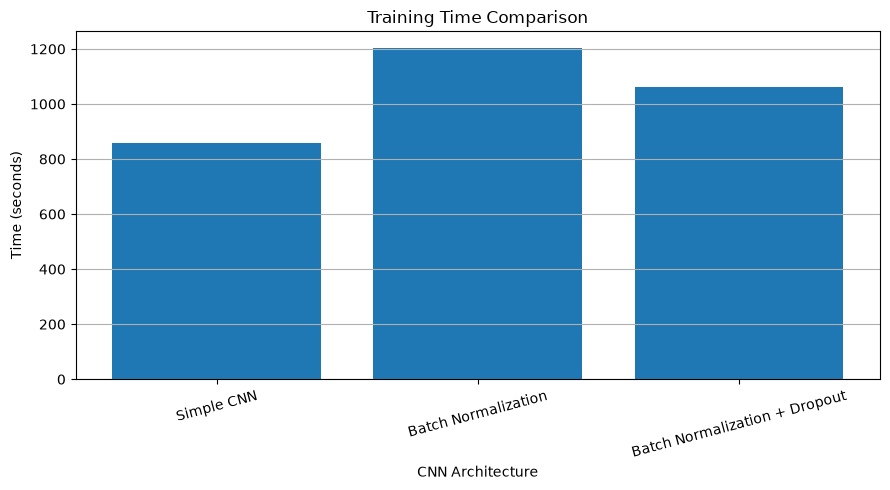

Fastest Model: Simple CNN
Training Time: 856.67 seconds


In [23]:

# Compare Training Speed

training_comparison = pd.DataFrame({
    "Model": [
        "Simple CNN",
        "Batch Normalization",
        "Batch Normalization + Dropout"
    ],
    "Training Time (seconds)": [
        simple_time,
        bn_time,
        dropout_time
    ]
})

print(training_comparison.to_string(index=False))

plt.figure(figsize=(9, 5))

plt.bar(
    training_comparison["Model"],
    training_comparison["Training Time (seconds)"]
)

plt.title("Training Time Comparison")
plt.xlabel("CNN Architecture")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

fastest_model = training_comparison.loc[
    training_comparison["Training Time (seconds)"].idxmin()
]

print("Fastest Model:", fastest_model["Model"])
print(
    "Training Time:",
    round(fastest_model["Training Time (seconds)"], 2),
    "seconds"
)


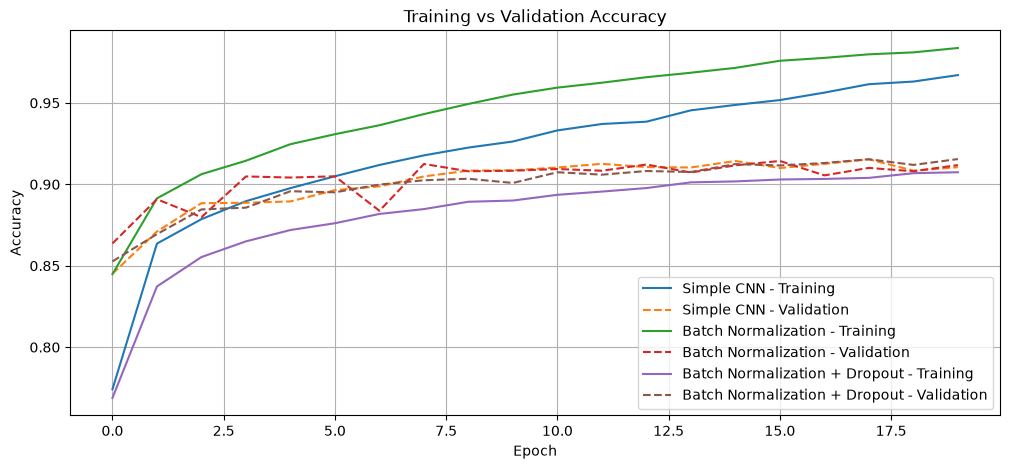

In [24]:

histories = {
    "Simple CNN": simple_history,
    "Batch Normalization": bn_history,
    "Batch Normalization + Dropout": dropout_history
}

plt.figure(figsize=(12, 5))

for name, history in histories.items():
    plt.plot(
        history["train_accuracy"],
        label=f"{name} - Training"
    )

    plt.plot(
        history["val_accuracy"],
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


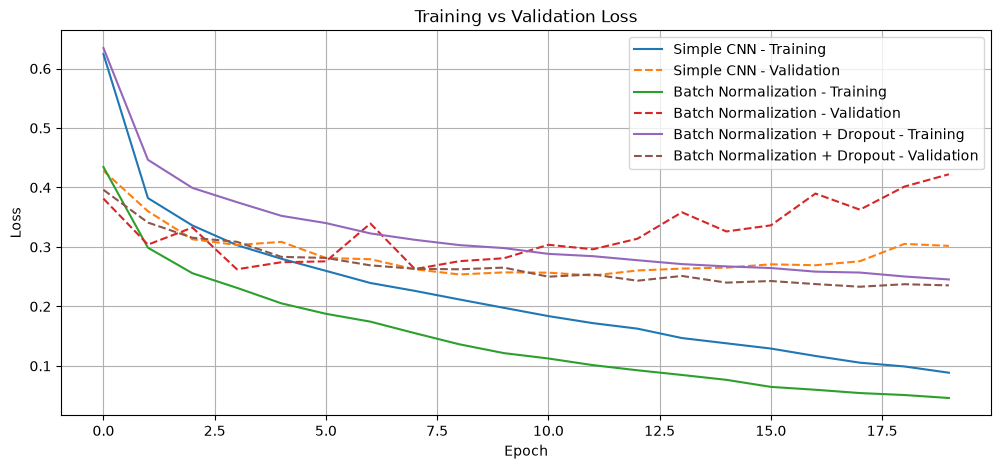

In [26]:

plt.figure(figsize=(12, 5))

for name, history in histories.items():

    plt.plot(
        history["train_loss"],
        label=f"{name} - Training"
    )

    plt.plot(
        history["val_loss"],
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


In [27]:

models = {
    "Simple CNN": simple_model,
    "Batch Normalization": bn_model,
    "Batch Normalization + Dropout": dropout_model
}

results = []

for name, model in models.items():

    test_loss, test_accuracy = evaluate_model(
        model, test_loader
    )

    training_time = {
        "Simple CNN": simple_time,
        "Batch Normalization": bn_time,
        "Batch Normalization + Dropout": dropout_time
    }[name]

    results.append({
        "Model": name,
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss,
        "Training Time (seconds)": training_time
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))


                        Model  Test Accuracy  Test Loss  Training Time (seconds)
                   Simple CNN         0.9173   0.256436               856.667434
          Batch Normalization         0.9159   0.308912              1203.713388
Batch Normalization + Dropout         0.9148   0.227151              1062.806100


   Model  Test Accuracy
Best MLP         0.8700
Best CNN         0.9173


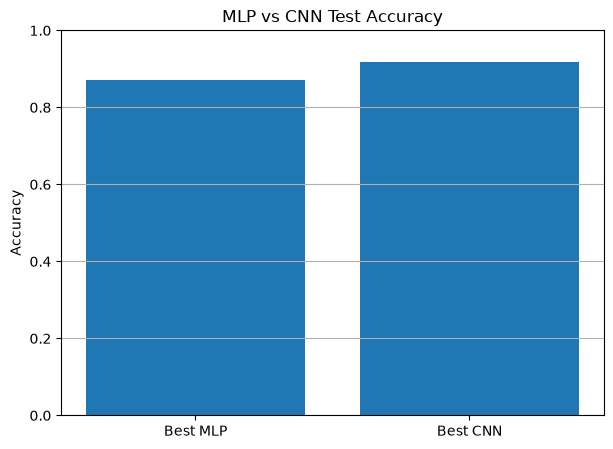

CNN performs better than MLP.
CNN improvement: 4.73 percentage points


In [28]:
# MLP vs CNN Accuracy Comparison

mlp_accuracy = 0.87  
cnn_accuracy = results_df["Test Accuracy"].max()

comparison_df = pd.DataFrame({
    "Model": ["Best MLP", "Best CNN"],
    "Test Accuracy": [mlp_accuracy, cnn_accuracy]
})

print(comparison_df.to_string(index=False))

plt.figure(figsize=(7, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy"]
)

plt.title("MLP vs CNN Test Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()

difference = abs(cnn_accuracy - mlp_accuracy) * 100

if cnn_accuracy > mlp_accuracy:
    print("CNN performs better than MLP.")
    print(f"CNN improvement: {difference:.2f} percentage points")

elif cnn_accuracy < mlp_accuracy:
    print("MLP performs better than CNN.")
    print(f"MLP improvement: {difference:.2f} percentage points")

else:
    print("Both models have equal accuracy.")

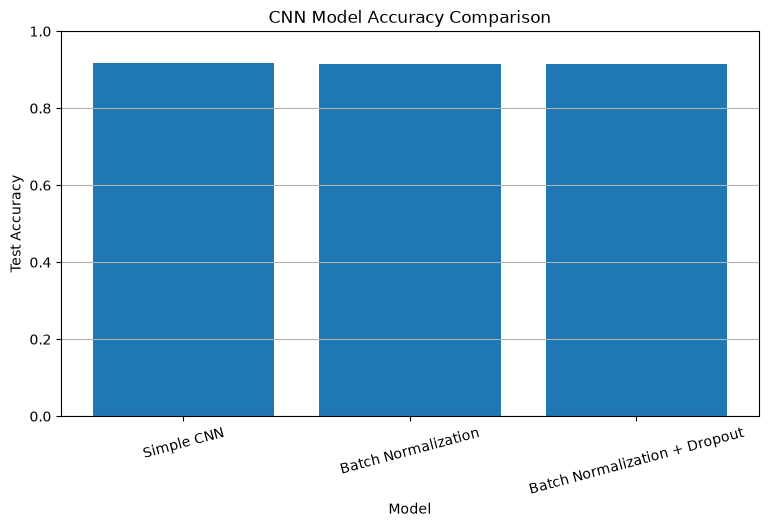

In [29]:

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Test Accuracy"]
)

plt.title("CNN Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.grid(axis="y")

plt.show()


In [30]:

best_model_name = max(
    histories,
    key=lambda name: max(histories[name]["val_accuracy"])
)

best_models = {
    "Simple CNN": simple_model,
    "Batch Normalization": bn_model,
    "Batch Normalization + Dropout": dropout_model
}

best_model = best_models[best_model_name]

print("Best CNN Model:", best_model_name)
print(
    "Best Validation Accuracy:",
    round(max(histories[best_model_name]["val_accuracy"]), 4)
)


Best CNN Model: Batch Normalization + Dropout
Best Validation Accuracy: 0.9155


      Model  Test Accuracy
0  Best MLP         0.8700
1  Best CNN         0.9173


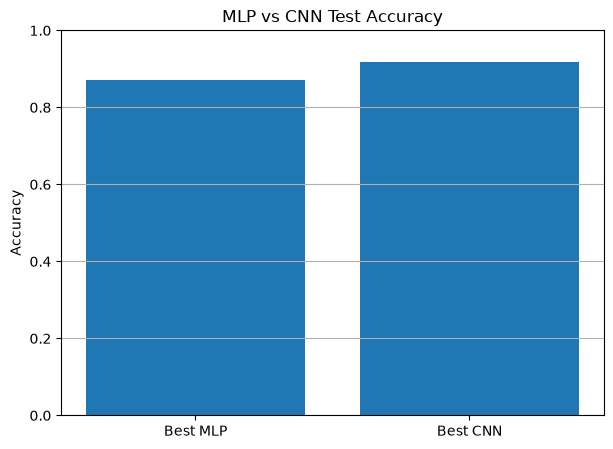

CNN performs better than MLP.


In [31]:

mlp_accuracy = 0.87  # Replace with your actual Assignment 1 accuracy

cnn_accuracy = results_df["Test Accuracy"].max()

comparison_df = pd.DataFrame({
    "Model": ["Best MLP", "Best CNN"],
    "Test Accuracy": [mlp_accuracy, cnn_accuracy]
})

print(comparison_df)

plt.figure(figsize=(7, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy"]
)

plt.title("MLP vs CNN Test Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()

if cnn_accuracy > mlp_accuracy:
    print("CNN performs better than MLP.")
elif cnn_accuracy < mlp_accuracy:
    print("MLP performs better than CNN.")
else:
    print("Both models have equal accuracy.")


In [32]:

def model_summary(model):

    model.eval()

    dummy_input = torch.zeros(
        1, 1, 28, 28
    ).to(DEVICE)

    layer_outputs = []
    hooks = []

    def hook_fn(module, inputs, output):

        if isinstance(output, torch.Tensor):

            params = sum(
                p.numel()
                for p in module.parameters(recurse=False)
            )

            layer_outputs.append({
                "Layer": module.__class__.__name__,
                "Output Shape": tuple(output.shape),
                "Parameters": params
            })

    for module in model.modules():

        if module != model and not isinstance(
            module, nn.Sequential
        ):
            hooks.append(
                module.register_forward_hook(hook_fn)
            )

    with torch.no_grad():
        model(dummy_input)

    for hook in hooks:
        hook.remove()

    summary_df = pd.DataFrame(layer_outputs)

    print(summary_df.to_string(index=False))

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print("\nTotal Parameters:", total_params)
    print("Trainable Parameters:", trainable_params)

model_summary(best_model)

      Layer    Output Shape  Parameters
     Conv2d (1, 32, 26, 26)         320
BatchNorm2d (1, 32, 26, 26)          64
       ReLU (1, 32, 26, 26)           0
  Dropout2d (1, 32, 26, 26)           0
  MaxPool2d (1, 32, 13, 13)           0
     Conv2d (1, 64, 11, 11)       18496
BatchNorm2d (1, 64, 11, 11)         128
       ReLU (1, 64, 11, 11)           0
  Dropout2d (1, 64, 11, 11)           0
  MaxPool2d   (1, 64, 5, 5)           0
    Flatten       (1, 1600)           0
     Linear        (1, 128)      204928
       ReLU        (1, 128)           0
    Dropout        (1, 128)           0
     Linear         (1, 10)        1290

Total Parameters: 225226
Trainable Parameters: 225226


First Conv Layer Filter Shape: (32, 1, 3, 3)


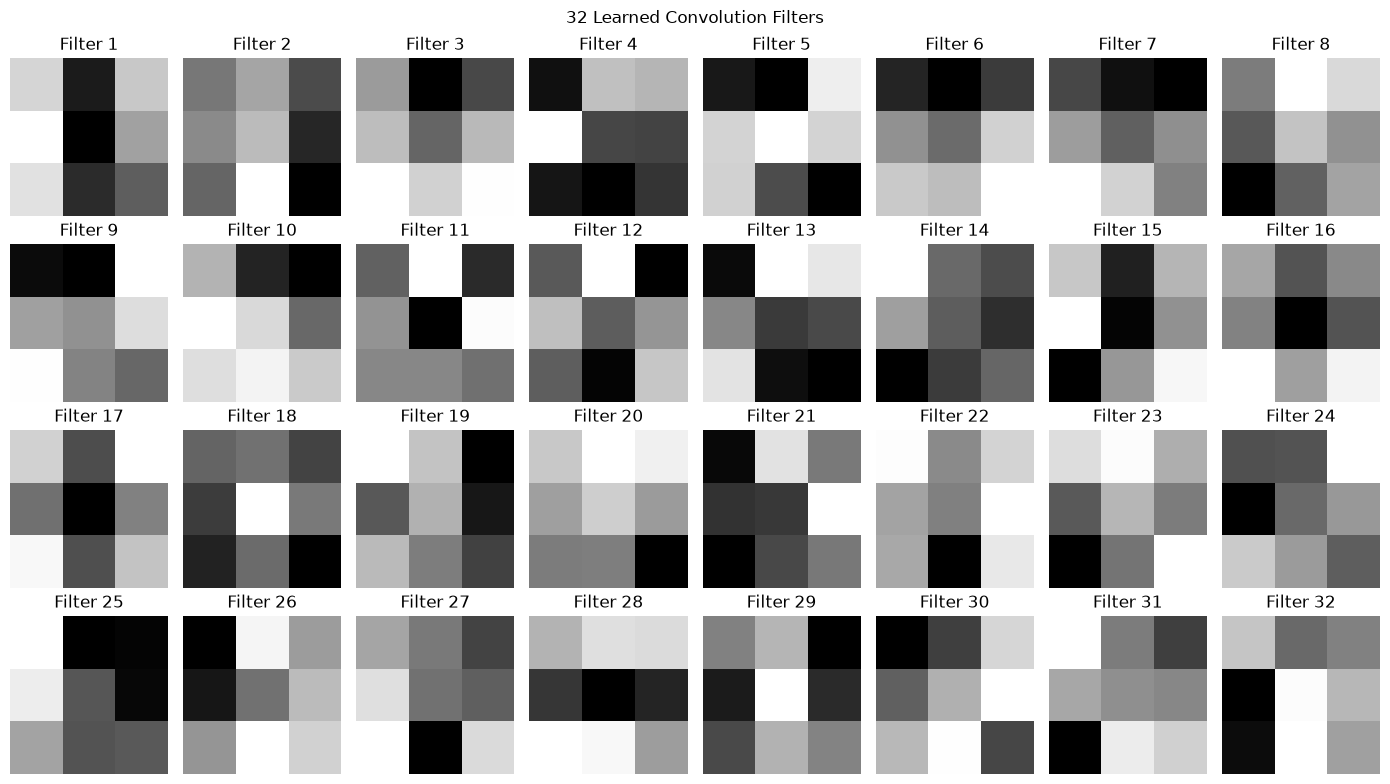

In [33]:

filters = best_model.conv1.weight.detach().cpu().numpy()

print("First Conv Layer Filter Shape:", filters.shape)

fig, axes = plt.subplots(4, 8, figsize=(14, 8))

for i, ax in enumerate(axes.flat):

    filter_image = filters[i, 0]

    ax.imshow(filter_image, cmap="gray")
    ax.set_title(f"Filter {i + 1}")
    ax.axis("off")

plt.suptitle("32 Learned Convolution Filters")
plt.tight_layout()
plt.show()


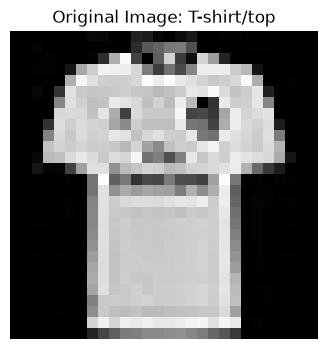

In [34]:

best_model.eval()

sample_inputs, sample_labels = next(iter(test_loader))

selected_image = sample_inputs[0:1].to(DEVICE)
selected_label = sample_labels[0].item()

plt.figure(figsize=(4, 4))

plt.imshow(
    selected_image[0, 0].cpu().numpy(),
    cmap="gray"
)

plt.title(
    f"Original Image: {class_names[selected_label]}"
)

plt.axis("off")
plt.show()


In [35]:

with torch.no_grad():

    feature_maps = best_model.conv1(selected_image)

    # Apply Batch Normalization if available
    if hasattr(best_model, "bn1"):
        feature_maps = best_model.bn1(feature_maps)

    feature_maps = torch.relu(feature_maps)

feature_maps = feature_maps.squeeze(0).cpu().numpy()

print("Feature Maps Shape:", feature_maps.shape)


Feature Maps Shape: (32, 26, 26)


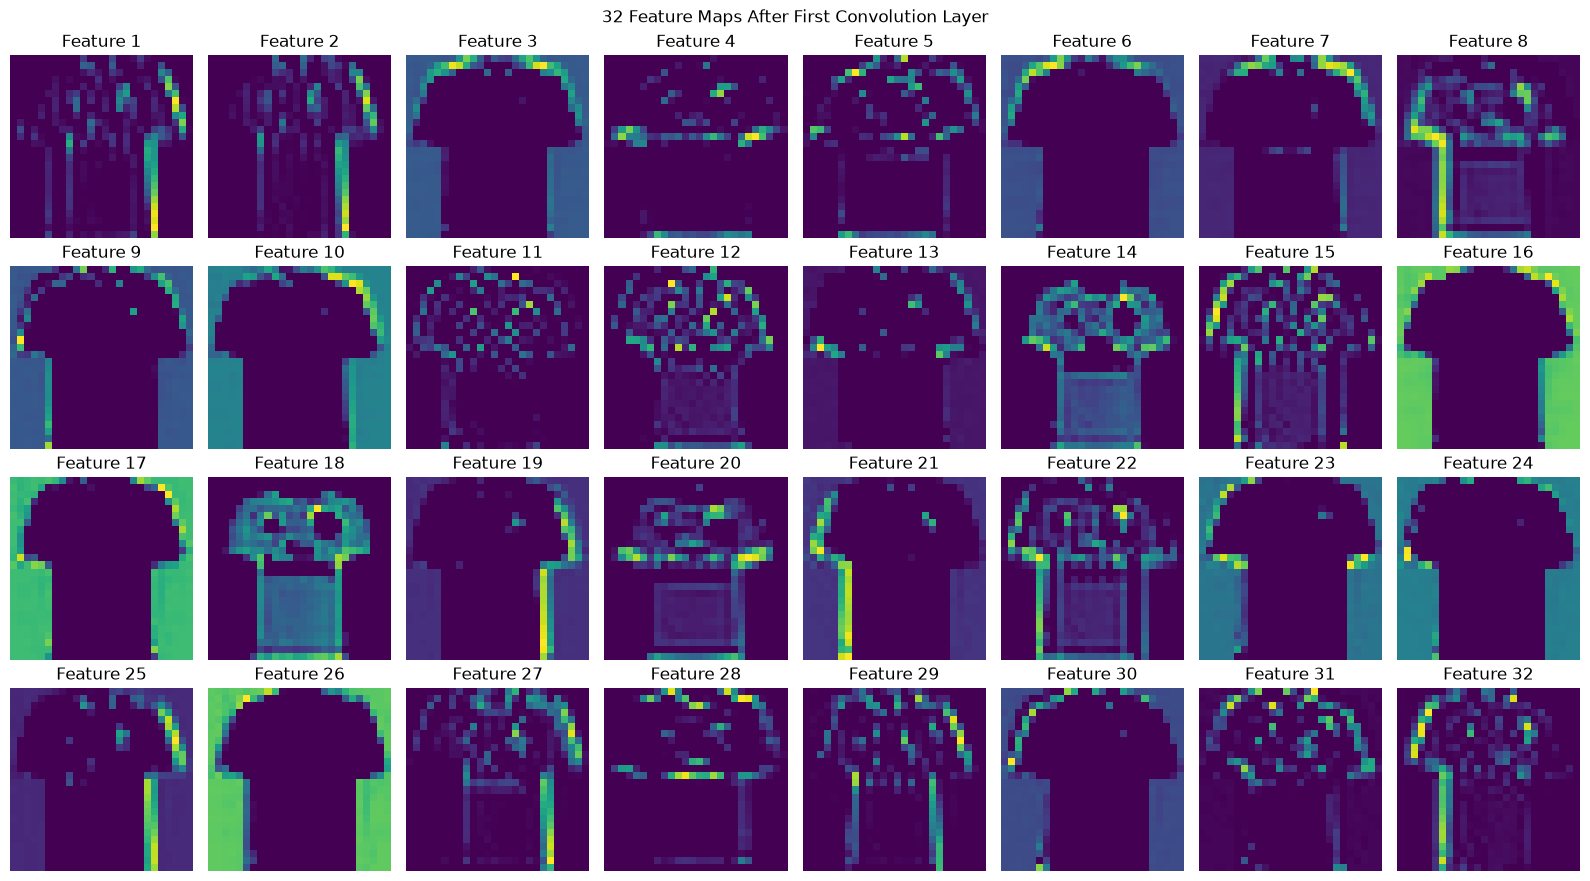

In [36]:

fig, axes = plt.subplots(4, 8, figsize=(16, 9))

for i, ax in enumerate(axes.flat):

    ax.imshow(feature_maps[i], cmap="viridis")
    ax.set_title(f"Feature {i + 1}")
    ax.axis("off")

plt.suptitle("32 Feature Maps After First Convolution Layer")
plt.tight_layout()
plt.show()


In [37]:

best_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(DEVICE)

        outputs = best_model(inputs)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

print("Total Predictions:", len(all_predictions))
print("Total Actual Labels:", len(all_labels))


Total Predictions: 10000
Total Actual Labels: 10000


In [38]:

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(10)),
        target_names=class_names,
        zero_division=0
    )
)


              precision    recall  f1-score   support

 T-shirt/top       0.86      0.85      0.86      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.92      0.83      0.87      1000
       Dress       0.92      0.93      0.92      1000
        Coat       0.86      0.90      0.88      1000
      Sandal       0.99      0.96      0.98      1000
       Shirt       0.73      0.78      0.75      1000
     Sneaker       0.96      0.95      0.95      1000
         Bag       0.99      0.98      0.99      1000
  Ankle boot       0.95      0.98      0.96      1000

    accuracy                           0.91     10000
   macro avg       0.92      0.91      0.92     10000
weighted avg       0.92      0.91      0.92     10000



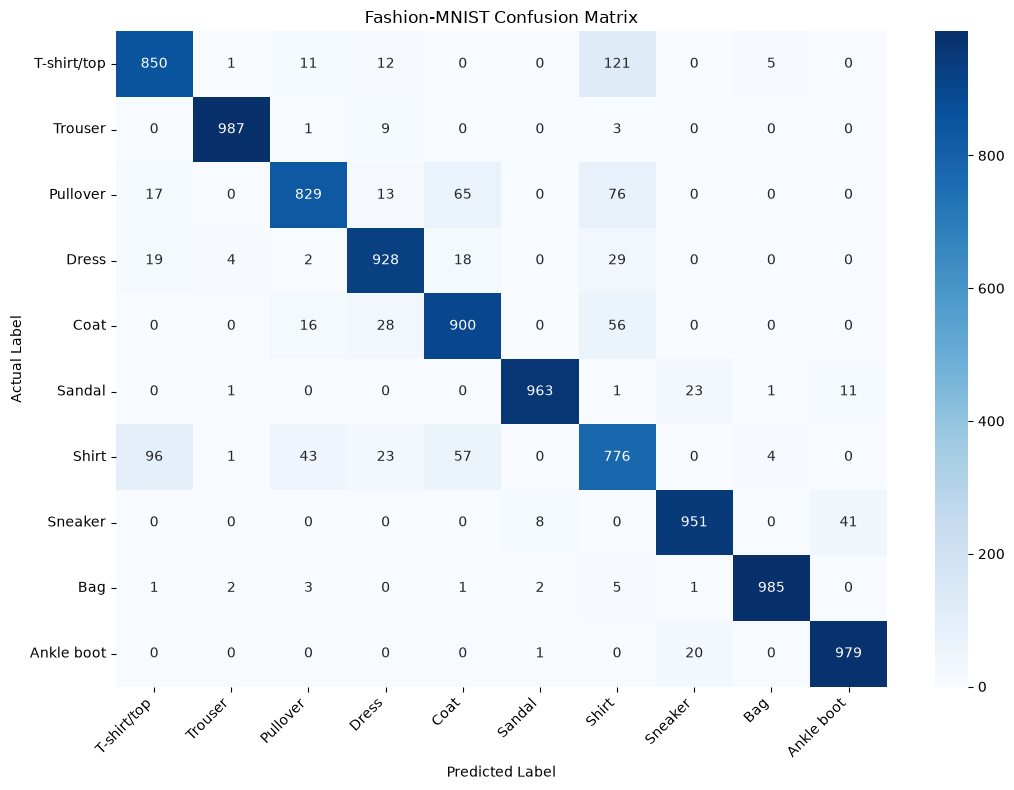

In [39]:

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Fashion-MNIST Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [40]:

class_accuracy = []

for i, class_name in enumerate(class_names):

    class_mask = all_labels == i

    total = np.sum(class_mask)

    correct = np.sum(
        all_predictions[class_mask] == all_labels[class_mask]
    )

    accuracy = (correct / total) * 100 if total > 0 else 0

    class_accuracy.append({
        "Class": class_name,
        "Correct": correct,
        "Total": total,
        "Accuracy (%)": accuracy
    })

class_accuracy_df = pd.DataFrame(class_accuracy)

print(
    class_accuracy_df.sort_values(
        "Accuracy (%)",
        ascending=False
    ).to_string(index=False)
)


      Class  Correct  Total  Accuracy (%)
    Trouser      987   1000          98.7
        Bag      985   1000          98.5
 Ankle boot      979   1000          97.9
     Sandal      963   1000          96.3
    Sneaker      951   1000          95.1
      Dress      928   1000          92.8
       Coat      900   1000          90.0
T-shirt/top      850   1000          85.0
   Pullover      829   1000          82.9
      Shirt      776   1000          77.6


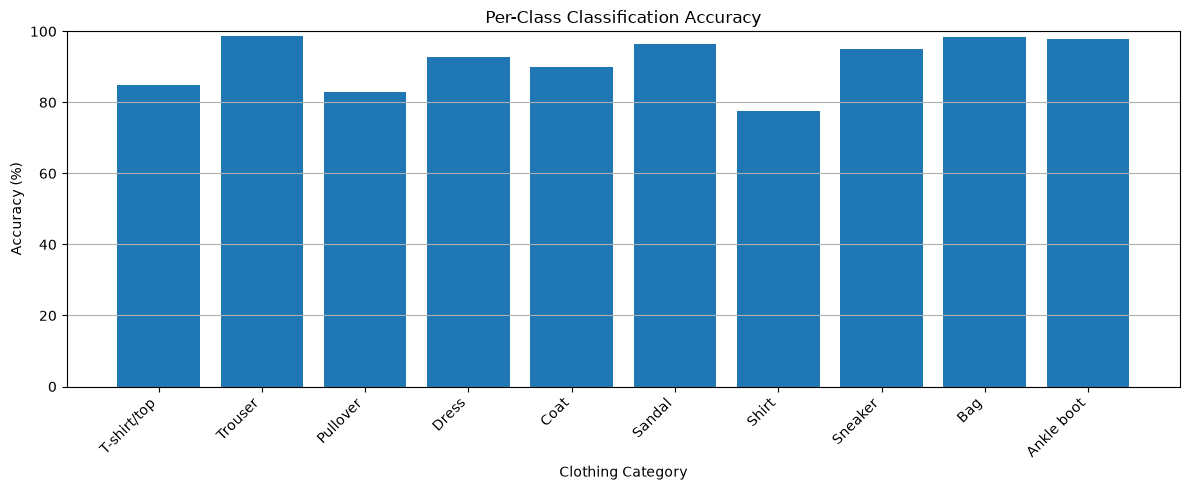

In [41]:

plt.figure(figsize=(12, 5))

plt.bar(
    class_accuracy_df["Class"],
    class_accuracy_df["Accuracy (%)"]
)

plt.title("Per-Class Classification Accuracy")
plt.xlabel("Clothing Category")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.grid(axis="y")

plt.tight_layout()
plt.show()


In [42]:

hardest_classes = class_accuracy_df.sort_values(
    "Accuracy (%)",
    ascending=True
).head(3)

print("Three Hardest Categories:\n")

print(hardest_classes.to_string(index=False))


Three Hardest Categories:

      Class  Correct  Total  Accuracy (%)
      Shirt      776   1000          77.6
   Pullover      829   1000          82.9
T-shirt/top      850   1000          85.0


In [43]:

confused_pairs = []

for i in range(NUM_CLASSES):

    for j in range(i + 1, NUM_CLASSES):

        confusion_count = cm[i, j] + cm[j, i]

        confused_pairs.append({
            "Clothing Pair": f"{class_names[i]} ↔ {class_names[j]}",
            "Confusion Count": confusion_count
        })

confused_pairs_df = pd.DataFrame(confused_pairs)

top_confused_pairs = confused_pairs_df.sort_values(
    "Confusion Count",
    ascending=False
).head(5)

print("Top 5 Most Confused Clothing Pairs:\n")

print(top_confused_pairs.to_string(index=False))


Top 5 Most Confused Clothing Pairs:

       Clothing Pair  Confusion Count
 T-shirt/top ↔ Shirt              217
    Pullover ↔ Shirt              119
        Coat ↔ Shirt              113
     Pullover ↔ Coat               81
Sneaker ↔ Ankle boot               61


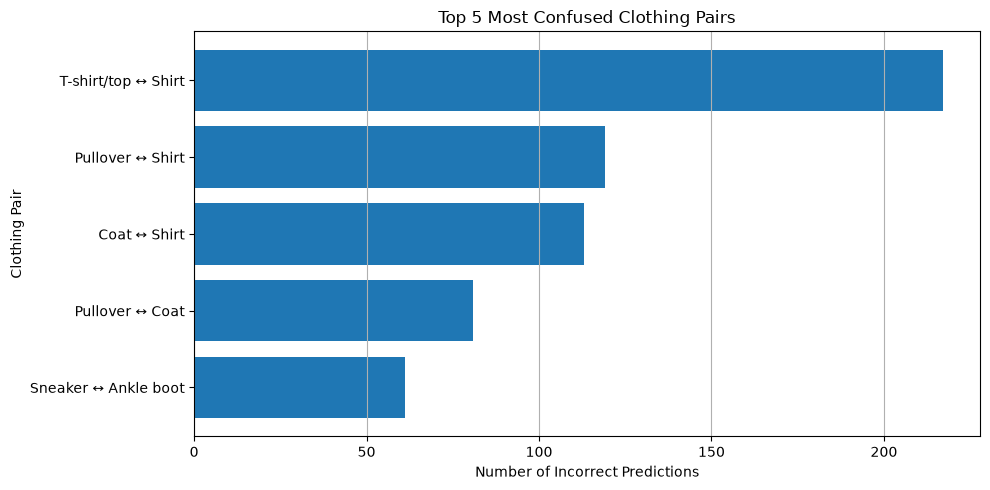

In [44]:

plt.figure(figsize=(10, 5))

plt.barh(
    top_confused_pairs["Clothing Pair"],
    top_confused_pairs["Confusion Count"]
)

plt.title("Top 5 Most Confused Clothing Pairs")
plt.xlabel("Number of Incorrect Predictions")
plt.ylabel("Clothing Pair")
plt.gca().invert_yaxis()
plt.grid(axis="x")

plt.tight_layout()
plt.show()


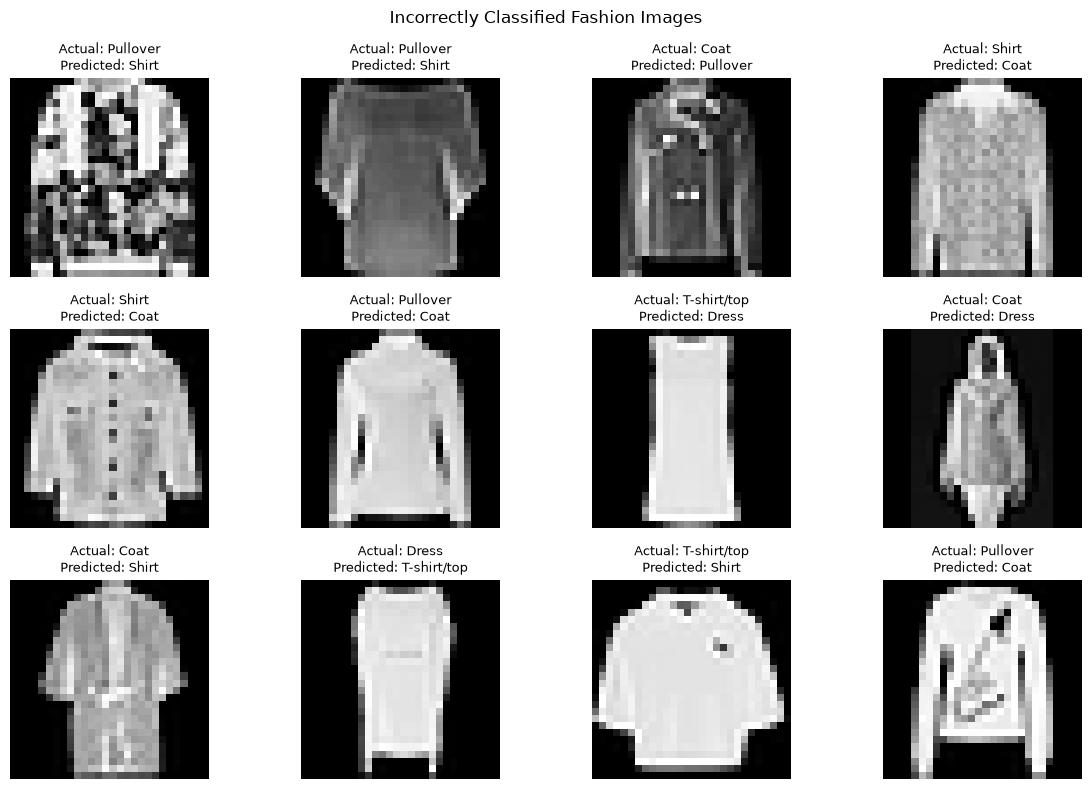

In [45]:

wrong_indices = np.where(
    all_predictions != all_labels
)[0]

plt.figure(figsize=(12, 8))

for i, index in enumerate(wrong_indices[:12]):

    image, actual_label = test_dataset[index]

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        image.squeeze().cpu().numpy(),
        cmap="gray"
    )

    predicted_label = all_predictions[index]

    plt.title(
        f"Actual: {class_names[actual_label]}\n"
        f"Predicted: {class_names[predicted_label]}",
        fontsize=9
    )

    plt.axis("off")

plt.suptitle("Incorrectly Classified Fashion Images")
plt.tight_layout()
plt.show()


In [46]:

torch.save(
    best_model.state_dict(),
    "fashion_mnist_cnn.pth"
)

print("Best CNN model saved successfully.")


Best CNN model saved successfully.


In [47]:

print("=" * 55)
print("FASHION-MNIST CNN PROJECT - FINAL RESULTS")
print("=" * 55)

print("\nDataset Information")
print("Training Samples:", len(train_dataset))
print("Validation Samples:", len(val_dataset))
print("Testing Samples:", len(test_dataset))
print("Number of Classes:", NUM_CLASSES)

print("\nModel Comparison")
print(results_df.to_string(index=False))

print("\nBest CNN Model:", best_model_name)

print(
    "Best CNN Test Accuracy:",
    f"{cnn_accuracy * 100:.2f}%"
)

print(
    "Best CNN Validation Accuracy:",
    f"{max(histories[best_model_name]['val_accuracy']) * 100:.2f}%"
)

print("\nHardest Clothing Categories:")

for _, row in hardest_classes.iterrows():
    print(
        row["Class"],
        "-",
        f"{row['Accuracy (%)']:.2f}%"
    )

print("\nMost Confused Clothing Pairs:")

for _, row in top_confused_pairs.head(3).iterrows():
    print(
        row["Clothing Pair"],
        "-",
        row["Confusion Count"],
        "mistakes"
    )

print("\nModel saved as fashion_mnist_cnn.pth")

print("=" * 55)


FASHION-MNIST CNN PROJECT - FINAL RESULTS

Dataset Information
Training Samples: 48000
Validation Samples: 12000
Testing Samples: 10000
Number of Classes: 10

Model Comparison
                        Model  Test Accuracy  Test Loss  Training Time (seconds)
                   Simple CNN         0.9173   0.256436               856.667434
          Batch Normalization         0.9159   0.308912              1203.713388
Batch Normalization + Dropout         0.9148   0.227151              1062.806100

Best CNN Model: Batch Normalization + Dropout
Best CNN Test Accuracy: 91.73%
Best CNN Validation Accuracy: 91.55%

Hardest Clothing Categories:
Shirt - 77.60%
Pullover - 82.90%
T-shirt/top - 85.00%

Most Confused Clothing Pairs:
T-shirt/top ↔ Shirt - 217 mistakes
Pullover ↔ Shirt - 119 mistakes
Coat ↔ Shirt - 113 mistakes

Model saved as fashion_mnist_cnn.pth
